Need to uploadd kaggle.json

In [34]:
!pip install kaggle --quiet
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"ninaddilipraojoshi","key":"b941439a0c3b28f9d4e7735d9a12e4b0"}'}

In [35]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.move("kaggle.json", "/root/.kaggle/kaggle.json")

os.chmod("/root/.kaggle/kaggle.json", 0o600)

In [36]:
!kaggle datasets download -d andrewmvd/animal-faces

Dataset URL: https://www.kaggle.com/datasets/andrewmvd/animal-faces
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)
animal-faces.zip: Skipping, found more recently modified local copy (use --force to force download)


In [37]:
import zipfile
import os

with zipfile.ZipFile("animal-faces.zip", "r") as zip_ref:
    zip_ref.extractall("animal-faces")

print(os.listdir("animal-faces"))

['afhq']


In [38]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader
from torchsummary import summary
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [39]:
from torchvision.transforms import transforms
from sklearn.preprocessing import LabelEncoder
from PIL import Image

Storing names and paths in pandas dataset

In [40]:
image_path = []
labels = []

for i in os.listdir("/content/animal-faces/afhq"):
  # print(i)
  for label in os.listdir(f"/content/animal-faces/afhq/{i}"):
    # print(label)
    for image in os.listdir(f"/content/animal-faces/afhq/{i}/{label}"):
      image_path.append(f"/content/animal-faces/afhq/{i}/{label}/{image}")
      labels.append(label)
      # print(image)
  #     break
  #   break
  # break
data_df = pd.DataFrame(zip(image_path, labels), columns = ["image_path", "labels"])
data_df.head()
print(data_df["labels"].unique())

['cat' 'dog' 'wild']


Splitting the dataset into train, test and validation set

In [41]:
train = data_df.sample(frac = 0.7)
test = data_df.drop(train.index)

val = test.sample(frac = 0.5)
test = test.drop(val.index)

print(train.shape, val.shape, test.shape)

(11291, 2) (2420, 2) (2419, 2)


In [42]:
# Label Encoding
label_encoder = LabelEncoder()
label_encoder.fit(data_df["labels"])

# Define Image Transformations
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.ConvertImageDtype(torch.float),
])

In [43]:
class CustomImageDataset(Dataset): # 'Dataset' interface used from pytorch.utils.data
  def __init__(self, dataframe, transform = None): # The __init__() method initializes the dataset when you create an object of this class.
    self.dataframe = dataframe
    self.transform = transform
    self.labels = torch.tensor(label_encoder.transform(dataframe["labels"])).to(device)

  def __len__(self): # returns number of samples in the dataset
    return self.dataframe.shape[0]

  def __getitem__(self, idx): # retrieves one sample at a specified index.
    img_path = self.dataframe.iloc[idx, 0] # The .iloc[] accessor retrieves data using integer positions.
    label = self.labels[idx]

    image = Image.open(img_path).convert('RGB')

    if self.transform:
      image = self.transform(image).to(device)

    return image, label

Executing the above method onto the dataset

In [44]:
train_dataset = CustomImageDataset(dataframe = train, transform = transform)
val_dataset = CustomImageDataset(dataframe = val, transform = transform)
test_dataset = CustomImageDataset(dataframe = test, transform = transform)

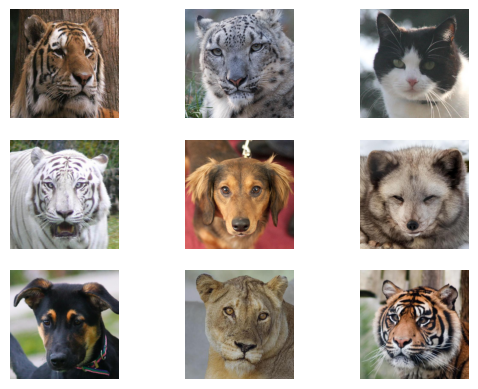

In [45]:
n_rows = 3
n_cols = 3

f, axarr = plt.subplots(n_rows, n_cols)

for row in range(n_rows):
  for col in range(n_cols):
    image = Image.open(data_df.sample(n = 1)["image_path"].iloc[0]).convert("RGB")
    axarr[row, col].imshow(image)
    axarr[row, col].axis('off')

plt.show()

In [46]:
LR = 1e-4
BATCH_SIZE = 16
EPOCHS = 10

A PyTorch Dataset stores information about individual samples and retrieves them one at a time. A DataLoader organizes those samples into batches and makes them available for model training and evaluation.

In [47]:
train_loader = DataLoader(train_dataset, batch_size = BATCH_SIZE, shuffle = True)
val_loader = DataLoader(val_dataset, batch_size = BATCH_SIZE, shuffle = True)
test_loader = DataLoader(test_dataset, batch_size = BATCH_SIZE, shuffle = True)

Model ArchitectureZ

In [48]:
class Net(nn.Module):
  def __init__(self):
    super().__init__()

# Definition
    self.conv1 = nn.Conv2d(3, 32, kernel_size = 3, padding = 1)
    self.conv2 = nn.Conv2d(32, 64, kernel_size = 3, padding = 1)
    self.conv3 = nn.Conv2d(64, 128, kernel_size = 3, padding = 1)

    self.pooling = nn.MaxPool2d(2, 2)
    self.relu = nn.ReLU()
    self.flatten = nn.Flatten()
    self.linear = nn.Linear((128*16*16), 128)
    self.output = nn.Linear(128, len(data_df['labels'].unique()))

# Model Flow
  def forward(self, x):
    x = self.conv1(x) # -> (32, 128, 128)
    x = self.pooling(x) # -> (32, 64, 64)
    x = self.relu(x)

    x = self.conv2(x) # -> (64, 64, 64)
    x = self.pooling(x) # -> (64, 32, 32)
    x = self.relu(x)

    x = self.conv3(x) # -> (128, 32, 32)
    x = self.pooling(x) # -> (128, 16, 16)
    x = self.relu(x)

    x = self.flatten(x)
    x = self.linear(x)
    x = self.output(x)

    return x

In [49]:
model = Net().to(device)

In [50]:
from torchsummary import summary
summary(model, input_size = (3, 128, 128))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
         MaxPool2d-2           [-1, 32, 64, 64]               0
              ReLU-3           [-1, 32, 64, 64]               0
            Conv2d-4           [-1, 64, 64, 64]          18,496
         MaxPool2d-5           [-1, 64, 32, 32]               0
              ReLU-6           [-1, 64, 32, 32]               0
            Conv2d-7          [-1, 128, 32, 32]          73,856
         MaxPool2d-8          [-1, 128, 16, 16]               0
              ReLU-9          [-1, 128, 16, 16]               0
          Flatten-10                [-1, 32768]               0
           Linear-11                  [-1, 128]       4,194,432
           Linear-12                    [-1, 3]             387
Total params: 4,288,067
Trainable params: 4,288,067
Non-trainable params: 0
---------------------------

In [51]:
criterion = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr = LR)

In [55]:
# Initialize lists to store metrics
total_loss_train_plot = []
total_loss_validation_plot = []
total_acc_train_plot = []
total_acc_validation_plot = []

for epoch in range(EPOCHS): # Iterate through epochs
  total_acc_train = 0
  total_loss_train = 0
  total_acc_val = 0
  total_loss_val = 0

  for inputs, label in train_loader: # Training loop
    optimizer.zero_grad() # Clear previous gradients

    outputs = model(inputs) # Forward propagation
    train_loss = criterion(outputs, label) # Calculate the loss
    total_loss_train += train_loss.item() # total_loss_train += train_loss.item()

    train_loss.backward() # Backpropagation
    optimizer.step() # Update the model parameters

    train_acc = (torch.argmax(outputs, axis=1) == label).sum().item() # Calculate training accuracy

    total_acc_train += train_acc
    optimizer.step()

# Validation loop
  with torch.no_grad(): # Disable gradient calculation
    for inputs, label in val_loader: # Validation loop
      outputs = model(inputs) # Generate predictions
      val_loss = criterion(outputs, label) # Calculate validation loss
      total_loss_val += val_loss.item()

      val_acc = (torch.argmax(outputs, axis=1) == label).sum().item() # Calculate validation accuracy
      total_acc_val += val_acc

  # Store the metrics after each epoch
  total_loss_train_plot.append(round(total_loss_train/1000, 4))
  total_loss_validation_plot.append(round(total_loss_val/1000, 4))

  total_acc_train_plot.append(round((total_acc_train/train_dataset.__len__())*100, 4))
  total_acc_validation_plot.append(round((total_acc_val/val_dataset.__len__())*100, 4))

  print(f'''Epoch {epoch+1}/{EPOCHS}, Train Loss: {round(total_loss_train/1000, 4)}, Train Accuracy: {round((total_acc_train/train_dataset.__len__())*100, 4)},
            Validation Loss: {round(total_loss_val/1000, 4)}, Validation Accuracy: {round((total_acc_val/val_dataset.__len__())*100, 4)}
          ''')

  #   print((torch.argmax(outputs, axis=1) == label))
  #   print(train_acc)
  #   break
  # break

Epoch 1/10, Train Loss: 0.105, Train Accuracy: 94.8632, 
            Validation Loss: 0.0165, Validation Accuracy: 96.3636
          
Epoch 2/10, Train Loss: 0.0658, Train Accuracy: 96.5902, 
            Validation Loss: 0.0242, Validation Accuracy: 93.595
          
Epoch 3/10, Train Loss: 0.0455, Train Accuracy: 97.7858, 
            Validation Loss: 0.0226, Validation Accuracy: 94.6694
          
Epoch 4/10, Train Loss: 0.0301, Train Accuracy: 98.5121, 
            Validation Loss: 0.0155, Validation Accuracy: 96.2397
          
Epoch 5/10, Train Loss: 0.0223, Train Accuracy: 98.8929, 
            Validation Loss: 0.0174, Validation Accuracy: 96.281
          
Epoch 6/10, Train Loss: 0.0167, Train Accuracy: 99.0966, 
            Validation Loss: 0.0131, Validation Accuracy: 96.9421
          
Epoch 7/10, Train Loss: 0.0096, Train Accuracy: 99.5749, 
            Validation Loss: 0.0155, Validation Accuracy: 96.8182
          
Epoch 8/10, Train Loss: 0.0065, Train Accuracy: 99.7697, 


Testing teh model

In [58]:
with torch.no_grad():
  total_loss_test = 0
  total_acc_test = 0
  for inputs, label in test_loader:
    predictions = model(inputs)

    acc = (torch.argmax(predictions, axis=1) == label).sum().item()
    total_acc_test += acc
    test_loss = criterion(predictions, label)
    total_loss_test += test_loss.item()

In [59]:
print(f"Accuracy score is: {round((total_acc_test/test_dataset.__len__())*100, 4)}")
print(f"Loss is: {round(total_loss_test/1000, 4)}")

Accuracy score is: 95.6594
Loss is: 0.0327


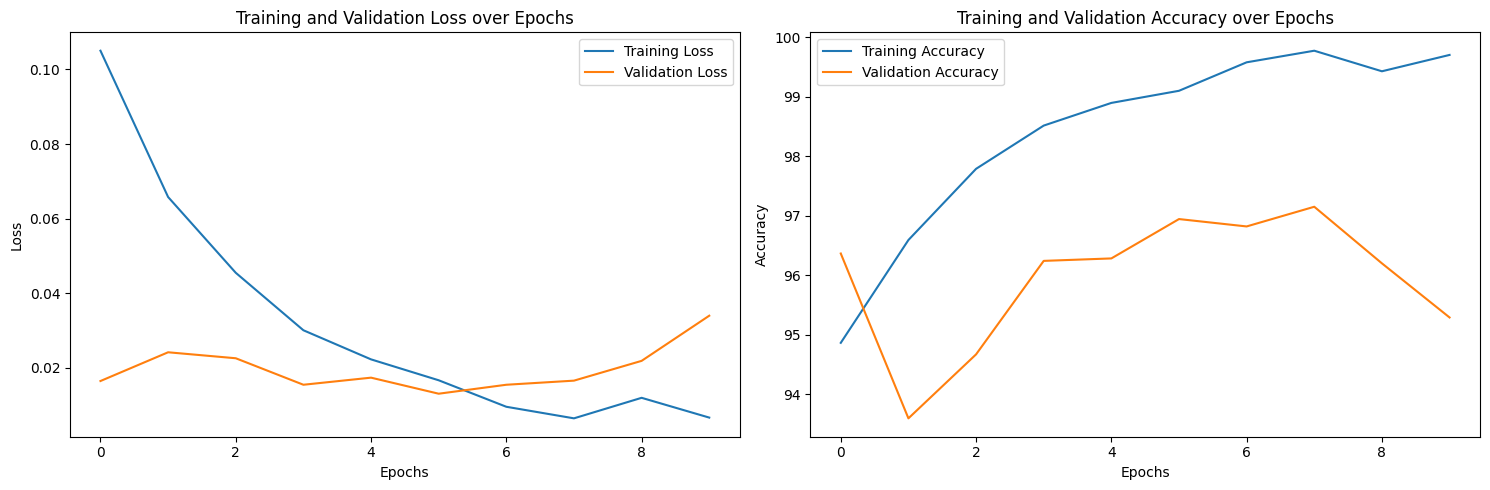

In [60]:

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

axs[0].plot(total_loss_train_plot, label='Training Loss')
axs[0].plot(total_loss_validation_plot, label='Validation Loss')
axs[0].set_title('Training and Validation Loss over Epochs')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].legend()

axs[1].plot(total_acc_train_plot, label='Training Accuracy')
axs[1].plot(total_acc_validation_plot, label='Validation Accuracy')
axs[1].set_title('Training and Validation Accuracy over Epochs')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].legend()

plt.tight_layout()

plt.show()

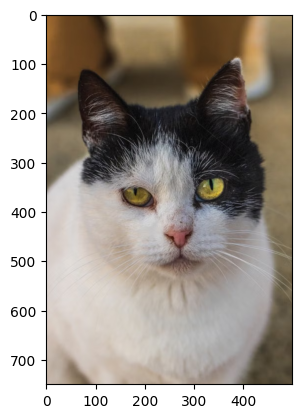


Prediction: 



array(['cat'], dtype=object)

In [67]:
# 1- read image
# 2- Transform using transform object
# 3- predict through the model
# 4- inverse transform by label encoder

def predict_image(image_path):
  image = Image.open(image_path).convert('RGB')
  image = transform(image).to(device)

  output = model(image.unsqueeze(0))
  output = torch.argmax(output, axis = 1).item()
  return label_encoder.inverse_transform([output])

## Visualize the image
image = Image.open("/content/pexels-photo-19542530.avif")
plt.imshow(image)
plt.show()


## Predict
print()
print("Prediction: \n")
predict_image("/content/pexels-photo-19542530.avif")